# krsim tutorial

This notebook runs every `krsim` command on a small simulation and shows what each one produces.

**Before you start**, install krsim from the repo root (see the main [README](../README.md#installation)):

```bash
pip install -e .
```

Then open this notebook from the `examples/` folder. Every command below is a normal terminal command — the `!` just runs it from inside the notebook, so you can copy them into a terminal as they are.

All outputs are written to `examples/output/`, and every file name ends in the random seed (`123` here).

In [1]:
import io
import ast
import pandas as pd
import matplotlib.pyplot as plt
import tskit

OUT = "output"
SEED = 123

## Stage 1 — simulate the transmission genealogy

A small run: 3 hosts, 10 generations, 2 parasites per bite. `--save_lineage` also keeps the true pedigree (needed for the two visualizations) and `--save_pairs` keeps same-meiosis strain pairs.

In [2]:
!krsim simulate --Nh 3 --T 10 --K 2 --chi 0.18 --C 1 --random_seed 123 --output_dir output --save_lineage --save_pairs

### tree sequence - ts_123.trees
### individual-node mapping - sim_ind_node_map_123.csv
### recombinant node pairs - node_pairs_123.csv
### strain lineage - lineage_123.csv
### node ID map (pre/post simplify) - node_id_map_123.csv


**`sim_ind_node_map_123.csv`** — which parasite strains (tree-sequence nodes) each host carries. `time` is generations before the present; `0` is the current generation.

In [3]:
hosts = pd.read_csv(f"{OUT}/sim_ind_node_map_{SEED}.csv")
current = hosts[hosts["time"] == 0]
print(f"{current['ind_id'].nunique()} current hosts carrying {len(current)} strains")
current.groupby("ind_id")["node_id"].apply(list).rename("strains").to_frame()

3 current hosts carrying 8 strains


,strains
ind_id,
8,"[0, 1, 2, 3]"
9,"[4, 5]"
10,"[6, 7]"


**`node_pairs_123.csv`** — pairs of strains produced by the same meiosis (only with `--save_pairs`). Comparing their genotypes in the strain VCF shows where recombination happened.

In [4]:
pd.read_csv(f"{OUT}/node_pairs_{SEED}.csv")

,sim_id,node_id,paired_node_id
0,123,2,3
1,123,4,5
2,123,15,16


**`lineage_123.csv`** — the true generation-by-generation pedigree (only with `--save_lineage`). The tree sequence is simplified, so it can skip generations; this table keeps every parent–child link.

In [5]:
lineage = pd.read_csv(f"{OUT}/lineage_{SEED}.csv")
print(f"{len(lineage)} parent–child links across {lineage['gen'].nunique()} generations")
lineage.head()

120 parent–child links across 10 generations


,sim_id,gen,child_node_ID,child_ind_ID,recomb_ID,parent_node_ID,parent_ind_ID
0,123,0.0,76,30,139,72,28
1,123,0.0,76,30,139,73,28
2,123,0.0,77,30,137,72,28
3,123,0.0,77,30,137,73,28
4,123,0.0,78,30,140,74,29


### Visualize the pedigree

Both visualizations only need Stage 1's `--save_lineage` files. Each writes a self-contained HTML page — open it in any web browser.

In [6]:
!krsim strain-transmission-map --lineage_csv output/lineage_123.csv --node_id_map_csv output/node_id_map_123.csv --random_seed 123 --output_dir output
!krsim pairwise-strain-pedigree-map --lineage_csv output/lineage_123.csv --node_id_map_csv output/node_id_map_123.csv --random_seed 123 --output_dir output

- `strain_transmission_map_123.html` — who infected whom, generation by generation. Click a strain to highlight its ancestors and descendants.
- `pairwise_strain_pedigree_map_123.html` — pick two current strains and trace them back to their shared pedigree ancestors.

## Stage 2 — add mutations

In [7]:
!krsim mutate --ts output/ts_123.trees --random_seed 123 --output_dir output

### mutated tree sequence - mutated_123.trees


In [8]:
ts = tskit.load(f"{OUT}/mutated_{SEED}.trees")
print(f"{ts.num_samples} sampled strains, {ts.num_trees} trees, {ts.num_mutations} mutations")

8 sampled strains, 193 trees, 727 mutations


## Stage 3 — coalescence and mutation times

In [9]:
!krsim coal --ts output/mutated_123.trees --random_seed 123 --output_dir output

**`coal_T_123.csv`** — for every pair of strains and every stretch of genome, when their ancestry last met (`coal_time`, in generations). Positions are relative to each chromosome.

In [10]:
coal = pd.read_csv(f"{OUT}/coal_T_{SEED}.csv")
coal.head()

,sample_1,sample_2,ancestor,chromosome,left,right,coal_time
0,0,1,10,1,0.0,74975.40906,1.0
1,0,4,14,1,0.0,74975.40906,2.0
2,0,5,14,1,0.0,74975.40906,2.0
3,0,6,14,1,0.0,74975.40906,2.0
4,0,7,14,1,0.0,74975.40906,2.0


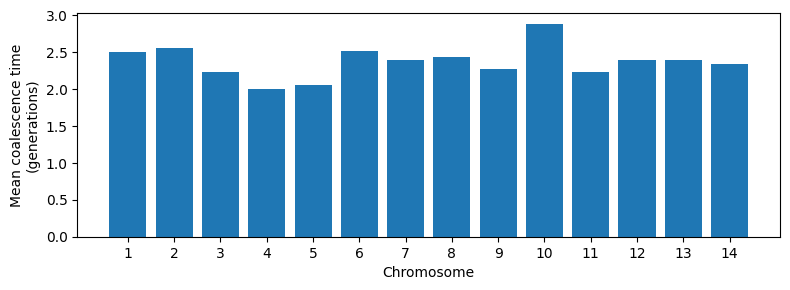

In [11]:
mean_coal = coal.groupby("chromosome")["coal_time"].mean()

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(mean_coal.index, mean_coal.values)
ax.set_xlabel("Chromosome")
ax.set_ylabel("Mean coalescence time\n(generations)")
ax.set_xticks(mean_coal.index)
plt.tight_layout()
plt.show()

**`mut_T_123.csv`** — every mutation: the node it sits on, its chromosome and position, and its age.

In [12]:
mut = pd.read_csv(f"{OUT}/mut_T_{SEED}.csv")
print(f"{len(mut)} mutations")
mut.head()

727 mutations


,node_id,chromosome,position,time
0,14,1,24145.0,6.115047
1,14,1,73960.0,4.697500
2,17,1,110207.0,7.082183
3,2,1,175031.0,0.655526
4,6,1,188126.0,0.428471


## Stage 4 — strain VCF

One haploid column per strain: `0` = reference allele, `1` = alternative allele.

In [13]:
!krsim vcf-strain --ts output/mutated_123.trees --random_seed 123 --output_dir output

In [14]:
def read_vcf(path):
    with open(path) as f:
        lines = [line for line in f if not line.startswith("##")]
    return pd.read_csv(io.StringIO("".join(lines)), sep="\t").rename(columns={"#CHROM": "CHROM"})

strain_vcf = read_vcf(f"{OUT}/output_{SEED}_strain.vcf")
print(f"{len(strain_vcf)} variant sites, {len(strain_vcf.columns) - 9} strains")
strain_vcf.head()

727 variant sites, 8 strains


,CHROM,POS,ID,REF,ALT,QUAL,FILTER,INFO,FORMAT,0,1,2,3,4,5,6,7
0,1,24145,0,A,G,.,PASS,.,GT,1,1,0,0,1,1,1,1
1,1,73960,1,C,G,.,PASS,.,GT,1,1,0,0,1,1,1,1
2,1,110207,2,C,A,.,PASS,.,GT,1,1,0,0,1,1,1,1
3,1,175031,3,T,C,.,PASS,.,GT,0,0,1,0,0,0,0,0
4,1,188126,4,A,C,.,PASS,.,GT,0,0,0,0,0,0,1,0


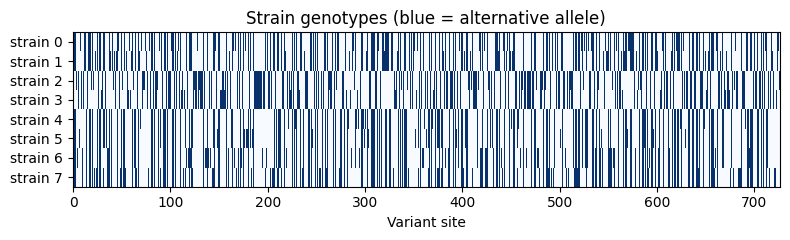

In [15]:
strains = strain_vcf.columns[9:]
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.imshow(strain_vcf[strains].astype(int).T, aspect="auto", cmap="Blues", interpolation="none")
ax.set_yticks(range(len(strains)))
ax.set_yticklabels([f"strain {s}" for s in strains])
ax.set_xlabel("Variant site")
ax.set_title("Strain genotypes (blue = alternative allele)")
plt.tight_layout()
plt.show()

## Stage 5 — host VCF

Mixes each host's strains the way sequencing a blood sample would: strain proportions are drawn from a Dirichlet, then `--depth` reads are shared out between the strains. A site is called `0/1` when the reads carry both alleles — a mixed infection.

In [16]:
!krsim vcf-host --strain_vcf output/output_123_strain.vcf --ind_node_map_csv output/sim_ind_node_map_123.csv --depth 10 --random_seed 123 --output_dir output --save_proportions

In [17]:
host_vcf = read_vcf(f"{OUT}/output_{SEED}_host.vcf")
host_vcf.head()

,CHROM,POS,ID,REF,ALT,QUAL,FILTER,INFO,FORMAT,8,9,10
0,1,24145,0,A,G,.,PASS,.,GT:AD:DP,"0/1:5,5:10","1/1:0,10:10","1/1:0,10:10"
1,1,73960,1,C,G,.,PASS,.,GT:AD:DP,"0/1:5,5:10","1/1:0,10:10","1/1:0,10:10"
2,1,110207,2,C,A,.,PASS,.,GT:AD:DP,"0/1:5,5:10","1/1:0,10:10","1/1:0,10:10"
3,1,175031,3,T,C,.,PASS,.,GT:AD:DP,"0/1:6,4:10","0/0:10,0:10","0/0:10,0:10"
4,1,188126,4,A,C,.,PASS,.,GT:AD:DP,"0/0:10,0:10","0/0:10,0:10","0/1:4,6:10"


**`host_proportions_123.csv`** (with `--save_proportions`) — each host's strain proportions and how many of the reads came from each strain.

In [18]:
props = pd.read_csv(f"{OUT}/host_proportions_{SEED}.csv")
for col in ["node_ids", "proportions", "reads"]:
    props[col] = props[col].apply(ast.literal_eval)
props

,sim_id,ind_id,node_ids,proportions,reads
0,123,8,"[0, 1, 2, 3]","[0.468668, 0.091878, 0.197678, 0.241776]","[3, 2, 4, 1]"
1,123,9,"[4, 5]","[0.237039, 0.762961]","[4, 6]"
2,123,10,"[6, 7]","[0.709162, 0.290838]","[6, 4]"


## True relatedness (IBD)

Because this is a simulation, we know the true identity-by-descent. `relate-strain` counts the fraction of the genome each pair of strains shares from a common ancestor within `--time_boundary` generations; `relate-host` averages that over the strains inside each current host.

In [19]:
!krsim relate-strain --coal_csv output/coal_T_123.csv --time_boundary 2 --random_seed 123 --output_dir output
!krsim relate-host --relate_csv output/relate_strain_123.csv --ind_node_map_csv output/sim_ind_node_map_123.csv --random_seed 123 --output_dir output

In [20]:
pd.read_csv(f"{OUT}/relate_strain_{SEED}.csv").head()

,sample_1,sample_2,frac_IBD
0,0,1,1.000000
1,0,4,0.462002
2,0,5,0.462002
3,0,6,0.491989
4,0,7,0.453065


In [21]:
pd.read_csv(f"{OUT}/relate_host_{SEED}.csv")

,host,avg_frac_IBD
0,8,0.333333
1,9,1.000000
2,10,0.718960


## Next steps

- `krsim <command> --help` lists every option for a command, with an example.
- The main [README](../README.md) has a diagram of which files each command reads and writes.
- Try a larger run by changing `--Nh`, `--T` and `--K` in Stage 1 (the two HTML visualizations are meant for small runs).